# code_216 · A prediction package includes the fitted transformation

**Book:** section 41.1. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_41_GUIDE.md), [execution evidence](../CHAPTER_41_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_216).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Deployment contracts bind source-fitted transformations, model state, schema and version. Resource measurements are actual observations of this run, separated from deterministic scientific results; no production service or autonomous engineering clearance is claimed. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8016;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8016


## Export the entire fitted contract, then reproduce it in another process
 Generate800 source structures with raw load/age and material in brick,steel,timber; some numeric fields are missing. Source-only median imputation and StandardScaler precede one-hot categories and logistic fitting. Bundle the imputation values, scaler centre/scale, category order, coefficient/intercept, event meaning, canonical units, feature order, format version and actual environment versions in canonical JSON. A new Python subprocess receives only those JSON bytes and raw records through stdin; its standard-library evaluator reconstructs transformations and probabilities without importing a parent helper or fitted estimator. Check200 independent final records. This is actual cross-process replay, not a claim that retraining across arbitrary library versions produces identical parameters. Public generated observations contain no private fields.


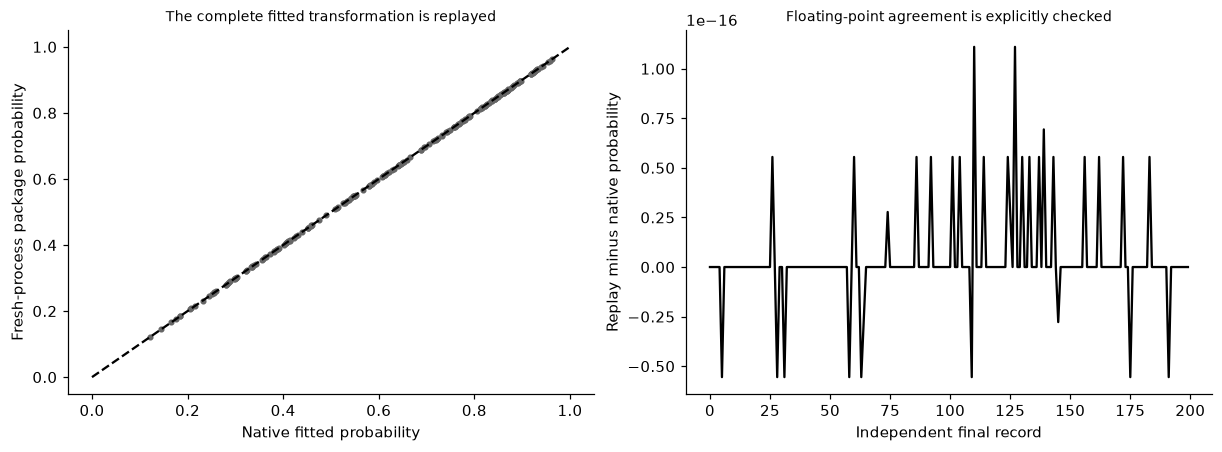

In [2]:
import hashlib,subprocess,sys
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
categories=['brick','steel','timber']
def cohort(n):
    values=np.c_[rng.uniform(0,10,n),rng.uniform(0,80,n)];material=rng.choice(categories,n);latent=-2+.35*values[:,0]+.015*values[:,1]+.4*(material=='timber');y=rng.binomial(1,expit(latent));values[rng.random(values.shape)<.05]=np.nan;return values,material,y
xs,cs,ys=cohort(800);xf,cf,yf=cohort(200);imputer=SimpleImputer(strategy='median').fit(xs);scaler=StandardScaler().fit(imputer.transform(xs))
def encode(x,c):return np.c_[scaler.transform(imputer.transform(x)),np.array([[int(v==name) for name in categories] for v in c])]
model=LogisticRegression(C=1,max_iter=400).fit(encode(xs,cs),ys);bundle={'format_version':1,'event':'generated actionable finding','canonical_load_unit':'kN','feature_order':['load','age','material'],'impute':imputer.statistics_.tolist(),'centre':scaler.mean_.tolist(),'scale':scaler.scale_.tolist(),'categories':categories,'coef':model.coef_[0].tolist(),'intercept':float(model.intercept_[0]),'environment':VERSIONS};blob=json.dumps(bundle,sort_keys=True,separators=(',',':'),allow_nan=False).encode();records=[{'load':None if np.isnan(row[0]) else float(row[0]),'age':None if np.isnan(row[1]) else float(row[1]),'material':material,'load_unit':'kN'} for row,material in zip(xf,cf)]
child=r"""
import sys,json,math
payload=json.load(sys.stdin);b=payload['bundle']
if b['format_version']!=1 or b['feature_order']!=['load','age','material']:raise ValueError('Unsupported package contract')
answer=[]
for r in payload['records']:
 if set(r)!={'load','age','material','load_unit'} or r['load_unit']!=b['canonical_load_unit'] or r['material'] not in b['categories']:raise ValueError('Invalid raw schema, units or category')
 values=[]
 for j,name in enumerate(['load','age']):
  value=b['impute'][j] if r[name] is None else float(r[name])
  if not math.isfinite(value):raise ValueError('Nonfinite numeric field')
  values.append((value-b['centre'][j])/b['scale'][j])
 values += [float(r['material']==c) for c in b['categories']]
 z=b['intercept']+sum(a*w for a,w in zip(values,b['coef']));p=1/(1+math.exp(-z)) if z>=0 else math.exp(z)/(1+math.exp(z));answer.append(p)
json.dump(answer,sys.stdout,allow_nan=False)
"""
def replay(package,raw):return subprocess.run([sys.executable,'-c',child],input=json.dumps({'bundle':package,'records':raw}),capture_output=True,text=True)
replayed=replay(bundle,records);assert replayed.returncode==0,replayed.stderr;from_child=np.array(json.loads(replayed.stdout));native=model.predict_proba(encode(xf,cf))[:,1];difference=float(np.max(abs(from_child-native)));assert difference<1e-12;assert np.all((from_child>=0)&(from_child<=1));RESULTS.update(source_structures=800,final_structures=200,package_format_version=1,package_bytes=len(blob),package_sha256=hashlib.sha256(blob).hexdigest(),fresh_process_max_probability_difference=difference,final_Brier=float(np.mean((native-yf)**2)),child_uses_parent_helpers=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].scatter(native,from_child,s=9,color='.4');axes[0].plot([0,1],[0,1],color='black',linestyle='--');axes[0].set(xlabel='Native fitted probability',ylabel='Fresh-process package probability',title='The complete fitted transformation is replayed');axes[1].plot(np.arange(200),from_child-native,color='black');axes[1].set(xlabel='Independent final record',ylabel='Replay minus native probability',title='Floating-point agreement is explicitly checked');plt.show()


## Reject incompatible requests instead of guessing a repair
 Test unknown material, wrong load unit, an unexpected control field and a format-version mismatch in separate fresh subprocesses; each must return failure. Missing numeric observations are explicitly permitted and use packaged source medians, while an unknown category is not silently mapped to a known one. The output contract is a probability of one named event, not authority to declare structural safety. VisualA connects source fitting to one package that feeds batch/online or solver-assisted consumers; a solver must retain its own domain and failure contract. JSON here contains only declarative fitted parameters and arrays; no untrusted executable model object is loaded. Digest consistency depends on retaining a trusted expected digest and does not authenticate a publisher by itself.


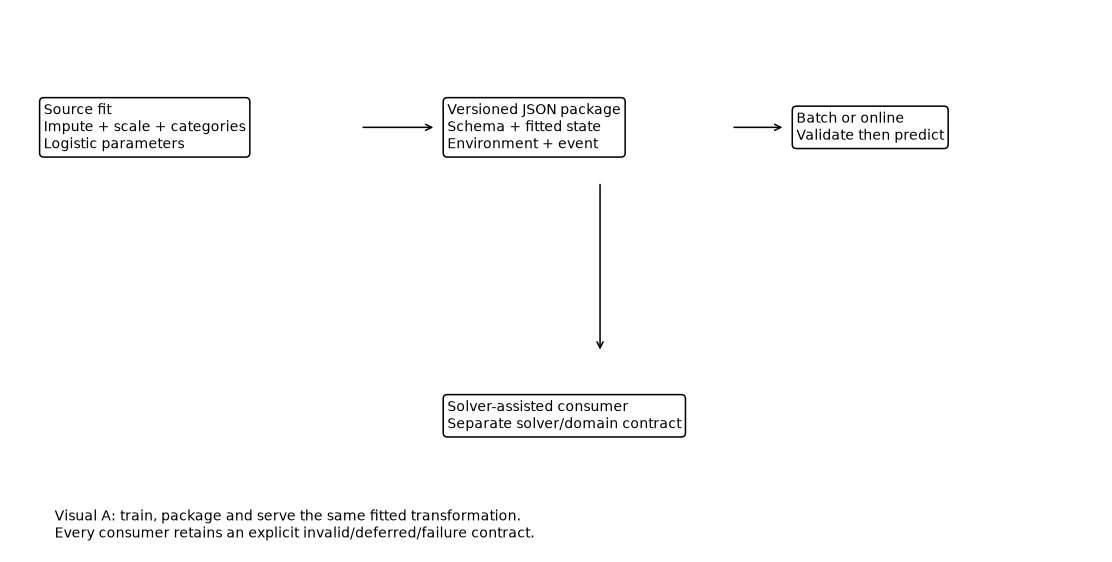

In [3]:
tests=[]
for name,record in [('unknown category',{**records[0],'material':'unknown'}),('wrong unit',{**records[0],'load_unit':'N'}),('unexpected field',{**records[0],'clearance':True})]:tests.append({'fixture':name,'rejected':replay(bundle,[record]).returncode!=0})
wrong=copy.deepcopy(bundle);wrong['format_version']=99;tests.append({'fixture':'unsupported format','rejected':replay(wrong,records[:1]).returncode!=0});assert all(r['rejected'] for r in tests);assert np.allclose(bundle['centre'],imputer.transform(xs).mean(0));assert bundle['environment']['scikit-learn']==sklearn.__version__;RESULTS.update(incompatible_request_fixtures=tests,missing_numeric_policy='source median imputation',unknown_category_policy='reject',schema_validity_is_not_structural_clearance=True);fig,ax=plt.subplots(figsize=(10,5));ax.axis('off');ax.set(xlim=(0,10),ylim=(0,6));items=[(.3,4.7,'Source fit\nImpute + scale + categories\nLogistic parameters'),(4.,4.7,'Versioned JSON package\nSchema + fitted state\nEnvironment + event'),(7.2,4.7,'Batch or online\nValidate then predict'),(4.,1.5,'Solver-assisted consumer\nSeparate solver/domain contract')]
for x,y,label in items:ax.text(x,y,label,va='center',fontsize=9,bbox={'boxstyle':'round','facecolor':'white','edgecolor':'black'})
for a,b in [((3.2,4.7),(3.9,4.7)),((6.6,4.7),(7.1,4.7)),((5.4,4.1),(5.4,2.2))]:ax.annotate('',xy=b,xytext=a,arrowprops={'arrowstyle':'->'})
ax.text(.4,.15,'Visual A: train, package and serve the same fitted transformation.\nEvery consumer retains an explicit invalid/deferred/failure contract.',fontsize=9);plt.show()


In [4]:
summary={'example_id':'code_216','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual source imputation scaling categories and logistic fit bundled as JSON', 'fresh subprocess reconstruction of raw-record probabilities using only bundled state', 'schema unit category and format-version validation fixtures', 'train package serve visual with reproducibility distinct from model validity'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual source imputation scaling categories and logistic fit bundled as JSON", "fresh subprocess reconstruction of raw-record probabilities using only bundled state", "schema unit category and format-version validation fixtures", "train package serve visual with reproducibility distinct from model validity"], "elapsed_seconds": 0.44, "example_id": "code_216", "hardware": "Darwin arm64 CPU", "resource_measurements": {}, "results": {"child_uses_parent_helpers": false, "final_Brier": 0.2254908834071111, "final_structures": 200, "fresh_process_max_probability_difference": 1.1102230246251565e-16, "incompatible_request_fixtures": [{"fixture": "unknown category", "rejected": true}, {"fixture": "wrong unit", "rejected": true}, {"fixture": "unexpected field", "rejected": true}, {"fixture": "unsupported format", "rejected": true}], "missing_numeric_policy": "source median imputation", "package_bytes": 600, "package_format_version": 1, "package_s